# 📘 Notebook 8 — Case Study 3.1: Styrene Free-Radical Polymerization
| | |
|---|---|
| ⏱ Time | ~20 min (simulations ≈ 30 s) |
| 🧭 Type | **steady state Monte Carlo** — isothermal CSTR at steady state |
| 🎯 Goal | reproduce **Table 3.3** and **Figures 3.3–3.6** of the book with the book's parameters |
| 📖 Book | Sec. 3.1 · Tables 3.1–3.3 · Algorithms 3.1 and 3.2 |

This notebook is about the **code**: how each equation and each line of the algorithm becomes Python. For the derivations, see *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture*.

**Mechanism (Table 3.1):** initiator decomposition `I → 2R` · initiation `R + M → P₁` · propagation `Pₙ + M → Pₙ₊₁` · transfer to monomer `Pₙ → Dₙ + P₁` · combination `Pₙ + Pₘ → Dₙ₊ₘ`.

## 0 · Setup
With `P_p ≈ 0.9997`, chains are ~5,000 units long, so 100,000 chains need about **10⁹ random numbers**. Pure Python would take minutes. We use **Numba** (preinstalled in Colab): the `@njit` decorator compiles a Python function to machine code (book Sec. 5.2, *Compilation versus Interpretation*). The code inside stays plain Python — you can read it line by line against the algorithm. The first call of each function takes a few seconds extra while it compiles.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit
plt.rcParams.update({"figure.figsize": (6, 3.8), "axes.grid": True, "grid.alpha": 0.3})

## 1 · Kinetic parameters (Table 3.2)
All rate constants follow the Arrhenius form `k = A·exp(−E/RT)`, with `E` in cal/mol and `R = 1.987` cal/(K·mol). Units are min⁻¹ and L/(mol·min).

In [2]:
R_gas = 1.987                      # cal/(K·mol)
T = 90 + 273.15                    # K
def arrhenius(A, E):
    return A * np.exp(-E / (R_gas * T))

kd  = arrhenius(1.6945e15, 31500)  # 1/min
kp  = arrhenius(1.302e9,   7759)   # L/(mol·min)
ktM = arrhenius(5.14e9,   15230)   # L/(mol·min)
ktc = arrhenius(4.92e11,   3470)   # L/(mol·min)
f   = 0.7                          # initiator efficiency
I   = 0.92e-3                      # mol/L
M   = 8.0                          # mol/L

pd.DataFrame({"value at 90 °C": [kd, kp, ktM, ktc]},
             index=["k_d (1/min)", "k_p (L/mol/min)", "k_tM (L/mol/min)", "k_tc (L/mol/min)"]).style.format("{:.4e}")

,value at 90 °C
k_d (1/min),1.8631e-04
k_p (L/mol/min),2.7844e+04
k_tM (L/mol/min),3.5037e+00
k_tc (L/mol/min),4.0132e+09


## 2 · From rate constants to probabilities
Step by step, as in Sec. 3.1:
- **QSSA** for the polymer radical concentration (Eq. 3.9): `[P] = √(f·k_d·[I] / k_tc)`
- **Probability of propagation** (Eq. 3.10): `P_p = k_p[M] / (k_p[M] + k_tM[M] + 2k_tc[P])`
- **Probability of combination** (Eq. 3.12): `P_tc = 2k_tc[P] / (2k_tc[P] + k_tM[M])`
- dimensionless groups for the analytical solution (Eqs. 3.15–3.16): `β = 2k_tc[P]/(k_p[M])`, `τ = k_tM/k_p`

In [3]:
P_rad = np.sqrt(f * kd * I / ktc)                                # Eq. 3.9
Pp  = kp*M / (kp*M + ktM*M + 2*ktc*P_rad)                        # Eq. 3.10
Ptc = 2*ktc*P_rad / (2*ktc*P_rad + ktM*M)                        # Eq. 3.12
beta = 2*ktc*P_rad / (kp*M)                                      # Eq. 3.15
tau  = ktM / kp                                                  # Eq. 3.16

pd.DataFrame({"this notebook": [P_rad, Pp, Ptc, beta, tau],
              "book": ["5.468e-09", "0.9997", "0.6102", "0.000197", "0.000126"]},
             index=["[P] (mol/L)", "P_p", "P_tc", "β", "τ"])

,this notebook,book
[P] (mol/L),5.467865e-09,5.468e-09
P_p,9.996772e-01,0.9997
P_tc,6.102455e-01,0.6102
β,1.970238e-04,0.000197
τ,1.258361e-04,0.000126


## 3 · The algorithms in code
### 3.1 · Growing one polymer radical
Lines 2–11 of Algorithms 3.1/3.2: start at `n = 1` (instantaneous initiation), then add one unit while `Rnd ≤ P_p`.

In [4]:
@njit
def grow_chain(Pp):
    n = 1                                   # initiation: chain of length 1
    while np.random.random() <= Pp:         # propagation?  Rnd ≤ P_p
        n += 1
    return n

### 3.2 · Algorithm 3.1 (contains the "unforgivable" flaw)
After the first chain stops, one more `Rnd` decides **how**: combination (`Rnd ≤ P_tc`) or transfer to monomer.

`D` is the **counting vector** of the book: `D[n]` = number of dead chains of length `n`. We allocate it once with plenty of room (`n_max`).

In [5]:
@njit
def algorithm_3_1(N, Pp, Ptc, n_max=500_000, seed=1):
    np.random.seed(seed)
    D = np.zeros(n_max, np.int64)
    for i in range(N):
        n = grow_chain(Pp)                  # lines 2–11
        if np.random.random() <= Ptc:       # line 13: combination
            m = grow_chain(Pp)              # lines 14–23: second chain (never checked!)
            D[n + m] += 1                   # line 24
        else:                               # line 25: transfer to monomer
            D[n] += 1                       # line 26
    return D

### 3.3 · Algorithm 3.2 (corrected)
The second radical must **also** decide how it terminates. If it picks transfer (`Rnd > P_tc`), it becomes a dead chain on its own (`D[m] += 1`), and we generate another partner — `repeat … until Rnd ≤ P_tc`. In Python, `repeat-until` becomes `while True: … if condition: break`.

In [6]:
@njit
def generate_second_chain(Pp, Ptc, D):
    while True:                             # line 14: repeat
        m = grow_chain(Pp)                  # lines 15–24
        if np.random.random() > Ptc:        # lines 25–26: partner transfers to monomer
            D[m] += 1                       # line 27
        else:                               # line 29: until Rnd ≤ P_tc
            return m

@njit
def algorithm_3_2(N, Pp, Ptc, n_max=500_000, seed=1):
    np.random.seed(seed)
    D = np.zeros(n_max, np.int64)
    for i in range(N):
        n = grow_chain(Pp)
        if np.random.random() <= Ptc:
            m = generate_second_chain(Pp, Ptc, D)
            D[n + m] += 1                   # line 30: Dₙ₊ₘ
        else:
            D[n] += 1                       # line 32
    return D

### 3.4 · Post-processing helpers
- Averages from the counting vector: `Nn = Σ n·D / Σ D`, `Nw = Σ n²·D / Σ n·D`
- Analytical (instantaneous) w-CLD, Eq. 3.14: `wₙ = n(β+τ)[τ + (β/2)(β+τ)n]·exp(−(β+τ)n)` and Eqs. 3.17–3.18 for `Nn`, `Nw`
- MC w-CLD: group chains into bins of width `Δn` (Sec. 2.3.1) and normalize by mass

In [7]:
def averages(D):
    n = np.arange(len(D), dtype=float)
    return (n*D).sum()/D.sum(), (n*n*D).sum()/(n*D).sum()

def analytical(beta, tau, n):
    s = beta + tau
    wn = n*s*(tau + 0.5*beta*s*n)*np.exp(-s*n)                   # Eq. 3.14
    return wn, 1/(tau + beta/2), (2*tau + 3*beta)/s**2           # Eqs. 3.17, 3.18

def mc_wcld(D, dn=200):
    n = np.arange(len(D))
    last = np.nonzero(D)[0].max()
    edges = np.arange(1, last + dn, dn)
    mass, _ = np.histogram(n, bins=edges, weights=n*D)
    centers = 0.5*(edges[1:] + edges[:-1])
    return centers, mass / mass.sum() / dn                       # normalized like wₙ

## 4 · Reproducing Table 3.3
Three cases: only combination (`τ = 0`), only transfer (`β = 0`), and both. For each case, `P_p = 1/(1 + β + τ)` and `P_tc = β/(β + τ)` — the same probabilities as above, written with β and τ.

In [8]:
cases = {"τ = 0, β = 0.000197": (beta, 0.0),
         "τ = 0.000126, β = 0": (0.0, tau),
         "τ = 0.000126, β = 0.000197": (beta, tau)}
book = {"τ = 0, β = 0.000197": (10159, 10151, 15246, 15227),
        "τ = 0.000126, β = 0": (7948, 7947, 15908, 15894),
        "τ = 0.000126, β = 0.000197": (4447, 4457, 8087, 8085)}

N = 100_000
results, rows = {}, {}
for name, (b, t) in cases.items():
    pp, ptc = 1/(1 + b + t), b/(b + t)
    D = algorithm_3_2(N, pp, ptc)
    results[name] = D
    Nn, Nw = averages(D)
    _, Nn_id, Nw_id = analytical(b, t, 1.0)
    rows[name] = [round(Nn), round(Nn_id), round(Nw), round(Nw_id), *book[name]]

pd.DataFrame(rows, index=["Nn (MC)", "Nn (ID)", "Nw (MC)", "Nw (ID)",
                          "book Nn (MC)", "book Nn (ID)", "book Nw (MC)", "book Nw (ID)"])

,"τ = 0, β = 0.000197","τ = 0.000126, β = 0","τ = 0.000126, β = 0.000197"
Nn (MC),10118,7941,4451
Nn (ID),10151,7947,4457
Nw (MC),15134,15842,8050
Nw (ID),15227,15894,8085
book Nn (MC),10159,7948,4447
book Nn (ID),10151,7947,4457
book Nw (MC),15246,15908,8087
book Nw (ID),15227,15894,8085


Monte Carlo values are stochastic, so they won't match the book to the last digit — but both should sit within ~0.5 % of the analytical (ID) solution.

## 5 · Figure 3.3: the two limiting cases

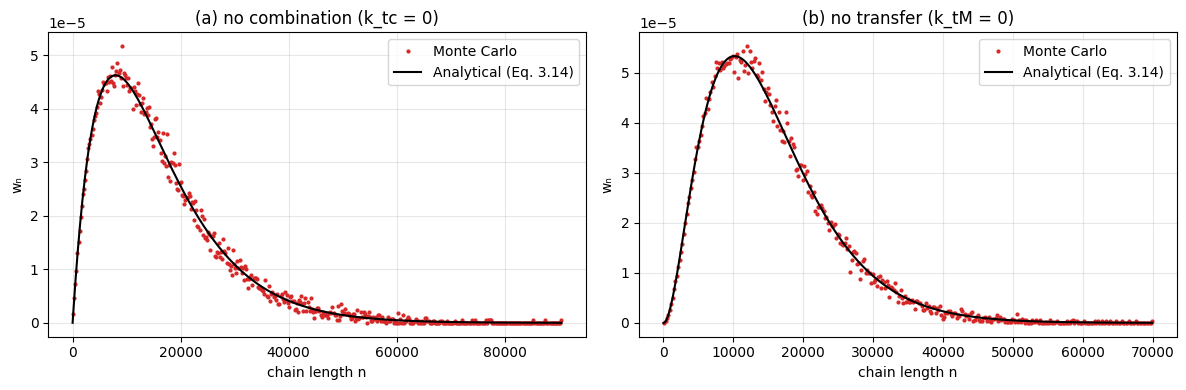

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, name, title in [(ax[0], "τ = 0.000126, β = 0", "(a) no combination (k_tc = 0)"),
                       (ax[1], "τ = 0, β = 0.000197", "(b) no transfer (k_tM = 0)")]:
    b, t = cases[name]
    x, w = mc_wcld(results[name])
    a.plot(x, w, ".", ms=4, c="tab:red", label="Monte Carlo")
    nn = np.linspace(1, x.max(), 600)
    a.plot(nn, analytical(b, t, nn)[0], "k-", label="Analytical (Eq. 3.14)")
    a.set_xlabel("chain length n"); a.set_ylabel("wₙ"); a.set_title(title); a.legend()
plt.tight_layout(); plt.show()

## 6 · Figures 3.4 and 3.6: catching the flaw
With **both** termination modes active, Algorithm 3.1 shifts the w-CLD to longer chains; Algorithm 3.2 matches the analytical solution.

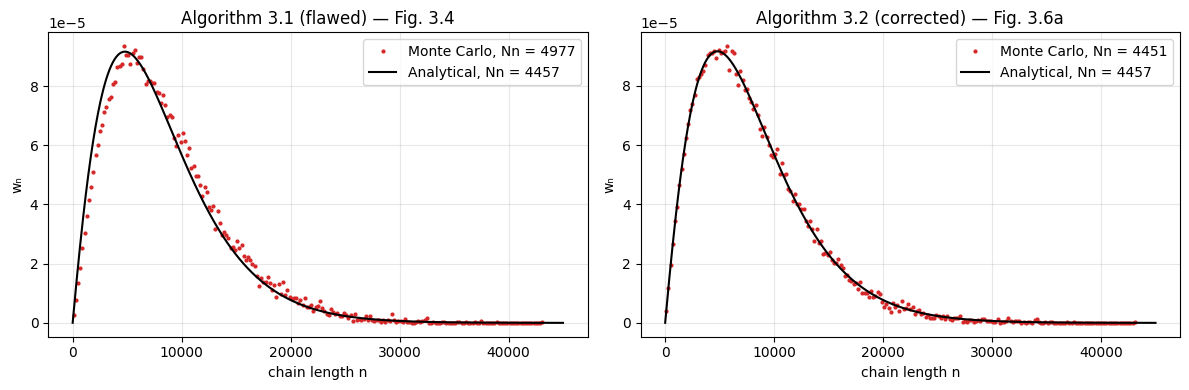

In [10]:
D_31 = algorithm_3_1(N, Pp, Ptc)
D_32 = results["τ = 0.000126, β = 0.000197"]
nn = np.linspace(1, 45_000, 600)
w_an, Nn_id, _ = analytical(beta, tau, nn)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, D, title in [(ax[0], D_31, "Algorithm 3.1 (flawed) — Fig. 3.4"), (ax[1], D_32, "Algorithm 3.2 (corrected) — Fig. 3.6a")]:
    x, w = mc_wcld(D)
    a.plot(x, w, ".", ms=4, c="tab:red", label=f"Monte Carlo, Nn = {averages(D)[0]:.0f}")
    a.plot(nn, w_an, "k-", label=f"Analytical, Nn = {Nn_id:.0f}")
    a.set_xlabel("chain length n"); a.set_ylabel("wₙ"); a.set_title(title); a.legend()
plt.tight_layout(); plt.show()

### Optional: Figure 3.6b with 1,000,000 chains
Ten times more chains → a visibly smoother w-CLD (≈ 1 min). Set `RUN_1M = True` to try it.

In [11]:
RUN_1M = False
if RUN_1M:
    D_1M = algorithm_3_2(1_000_000, Pp, Ptc, seed=2)
    x, w = mc_wcld(D_1M)
    plt.plot(x, w, ".", ms=3, c="tab:red", label="Monte Carlo, N = 10⁶")
    plt.plot(nn, w_an, "k-", label="Analytical")
    plt.xlabel("chain length n"); plt.ylabel("wₙ"); plt.legend(); plt.show()

## ✅ What the code taught us
- Every probability is a ratio of rates; the QSSA gives the one unknown concentration, `[P]`.
- The algorithm is a **direct translation** of the decision tree — and the decision loops must mirror the mechanism exactly. One missing check (the partner radical's termination) shifts the whole distribution.
- Always validate against limiting cases or analytical solutions when they exist.

### 🧪 Try it yourself
1. Change the temperature to 70 °C. Recompute the probabilities: which way does Nn move, and why?
2. Double `[I]`. Which probability changes, and by how much?
3. Replace `grow_chain` with geometric sampling (`np.random.geometric(1 − P_p)`) and compare the run time (book Sec. 5.3).

➡️ **Next: Notebook 9 — Case Study 3.2: styrene/MMA copolymerization**